# MỤC 3 – KIỂM ĐỊNH GIẢ THUYẾT

| Câu | Câu hỏi nghiên cứu | Kiểm định |
|---|---|---|
| 1 | Người hút thuốc có chi phí bảo hiểm cao hơn người không hút thuốc không? | Welch t-test (một phía) |
| 2 | Giới tính có liên quan đến tình trạng hút thuốc không? | Chi-square độc lập |

Mức ý nghĩa: α = 0,05.

## 0. Chuẩn bị: thư viện, dữ liệu, hàm dùng chung

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
ALPHA = 0.05

df = pd.read_csv("../shared/insurance.csv").drop_duplicates()   
print("Kích thước dữ liệu:", df.shape)

Kích thước dữ liệu: (1337, 7)


In [4]:
def kiem_tra_gia_dinh(nhom_a, nhom_b, ten_a, ten_b):
    """Shapiro-Wilk cho từng nhóm và Levene cho tính đồng nhất phương sai."""
    for ten, g in [(ten_a, nhom_a), (ten_b, nhom_b)]:
        w, p = stats.shapiro(g)
        print(f"Shapiro-Wilk [{ten}]: W={w:.4f}, p={p:.4g}, skew={stats.skew(g):.2f}")
    lev = stats.levene(nhom_a, nhom_b)
    print(f"Levene: stat={lev.statistic:.2f}, p={lev.pvalue:.4g}")
    return lev.pvalue


def welch_ttest(nhom_a, nhom_b, alternative="two-sided"):
    """Welch t-test, trả về t, df, p, hiệu trung bình, KTC 95% và Cohen's d."""
    t, p = stats.ttest_ind(nhom_a, nhom_b, equal_var=False, alternative=alternative)
    va, vb = nhom_a.var() / len(nhom_a), nhom_b.var() / len(nhom_b)
    se = np.sqrt(va + vb)
    df_w = (va + vb) ** 2 / (va**2 / (len(nhom_a) - 1) + vb**2 / (len(nhom_b) - 1))
    diff = nhom_a.mean() - nhom_b.mean()
    margin = stats.t.ppf(0.975, df_w) * se
    d = diff / np.sqrt((nhom_a.var() + nhom_b.var()) / 2)
    return {"t": t, "df": df_w, "p": p, "diff": diff, "ci": (diff - margin, diff + margin), "d": d}


def ket_luan(p, alpha=ALPHA):
    print("=> Bác bỏ H0" if p < alpha else "=> Không đủ bằng chứng bác bỏ H0")

## 1. Câu 1 – t-test: chi phí bảo hiểm theo tình trạng hút thuốc
- **H₀:** μ_hút thuốc = μ_không hút thuốc
- **H₁:** μ_hút thuốc > μ_không hút thuốc (kiểm định một phía vì câu hỏi hỏi "cao hơn")

In [5]:
yes = df.loc[df.smoker == "yes", "charges"]
no = df.loc[df.smoker == "no", "charges"]
print(f"Hút thuốc : n={len(yes)}, mean={yes.mean():.2f}, sd={yes.std():.2f}")
print(f"Không hút : n={len(no)}, mean={no.mean():.2f}, sd={no.std():.2f}")

Hút thuốc : n=274, mean=32050.23, sd=11541.55
Không hút : n=1063, mean=8440.66, sd=5992.97


**Kiểm tra giả định.** Charges lệch phải nên Shapiro-Wilk bác bỏ phân phối chuẩn. Tuy nhiên mẫu lớn (274 và 1063) và Levene cho thấy phương sai khác nhau, vì vậy dùng **Welch t-test**.

In [6]:
kiem_tra_gia_dinh(yes, no, "smoker=yes", "smoker=no")
kq = welch_ttest(yes, no, alternative="greater")
print(f"Welch t-test (một phía): t={kq['t']:.3f}, df={kq['df']:.1f}, p={kq['p']:.4g}")
print(f"Hiệu trung bình = {kq['diff']:.2f}, KTC 95% = ({kq['ci'][0]:.2f}, {kq['ci'][1]:.2f})")
print(f"Cohen's d = {kq['d']:.2f}; người hút thuốc trả gấp {yes.mean() / no.mean():.1f} lần")
ket_luan(kq["p"])

# Đối chiếu bằng kiểm định phi tham số và dữ liệu log (do charges lệch phải)
_, p_mw = stats.mannwhitneyu(yes, no, alternative="greater")
_, p_log = stats.ttest_ind(np.log(yes), np.log(no), equal_var=False, alternative="greater")
print(f"[Đối chiếu] Mann-Whitney: p={p_mw:.4g} | t-test trên log(charges): p={p_log:.4g}")

Shapiro-Wilk [smoker=yes]: W=0.9396, p=3.625e-09, skew=0.13
Shapiro-Wilk [smoker=no]: W=0.8729, p=1.504e-28, skew=1.54
Levene: stat=332.47, p=1.67e-66
Welch t-test (một phía): t=32.742, df=311.9, p=3.131e-103
Hiệu trung bình = 23609.57, KTC 95% = (22190.79, 25028.35)
Cohen's d = 2.57; người hút thuốc trả gấp 3.8 lần
=> Bác bỏ H0
[Đối chiếu] Mann-Whitney: p=2.874e-130 | t-test trên log(charges): p=3.392e-234


## 2. Câu 2 – Chi-square: giới tính và tình trạng hút thuốc
- **H₀:** `sex` và `smoker` độc lập
- **H₁:** `sex` và `smoker` có liên quan

In [7]:
ct = pd.crosstab(df.sex, df.smoker)
print("Bảng tần số quan sát:\n", ct)
print("\nTỷ lệ (%) hút thuốc theo giới tính:\n",
      (pd.crosstab(df.sex, df.smoker, normalize="index") * 100).round(2))

Bảng tần số quan sát:
 smoker   no  yes
sex             
female  547  115
male    516  159

Tỷ lệ (%) hút thuốc theo giới tính:
 smoker     no    yes
sex                 
female  82.63  17.37
male    76.44  23.56


In [8]:
chi2, p2, dof, expected = stats.chi2_contingency(ct, correction=False)
print("Tần số kỳ vọng:\n", pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1))
print(f"Giả định: tần số kỳ vọng nhỏ nhất = {expected.min():.1f} (>= 5: thỏa)")

chi2_y, p_y, _, _ = stats.chi2_contingency(ct, correction=True)   # hiệu chỉnh Yates cho bảng 2x2
V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi2={chi2:.3f}, dof={dof}, p={p2:.4f} | Yates: chi2={chi2_y:.3f}, p={p_y:.4f}")
print(f"Cramér's V = {V:.3f}")
ket_luan(p2)

Tần số kỳ vọng:
 smoker     no    yes
sex                 
female  526.3  135.7
male    536.7  138.3
Giả định: tần số kỳ vọng nhỏ nhất = 135.7 (>= 5: thỏa)
Chi2=7.844, dof=1, p=0.0051 | Yates: chi2=7.469, p=0.0063
Cramér's V = 0.077
=> Bác bỏ H0


## 3. Trực quan hóa

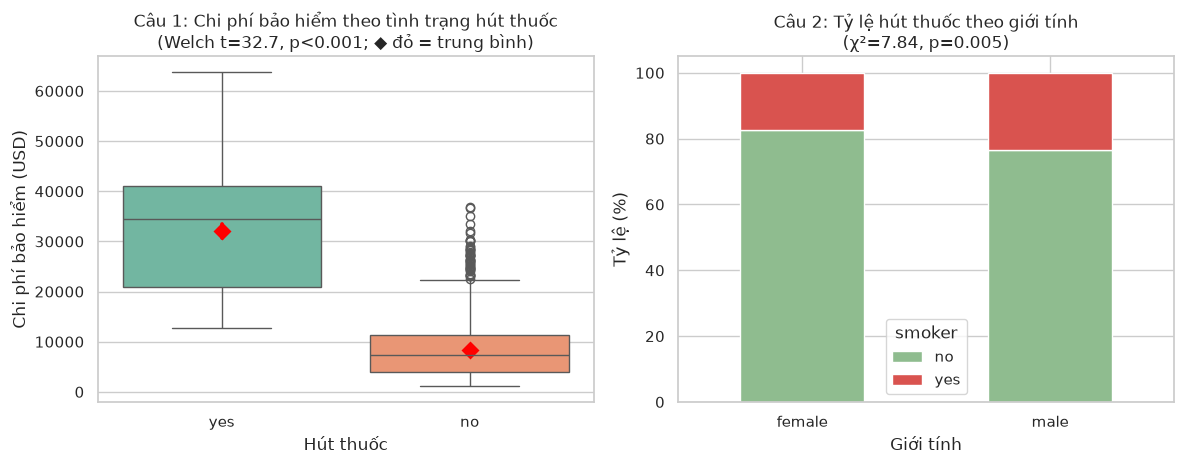

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", palette="Set2", legend=False, ax=ax[0])
sns.pointplot(data=df, x="smoker", y="charges", color="red", linestyle="none", markers="D", ax=ax[0])
ax[0].set_title(f"Câu 1: Chi phí bảo hiểm theo tình trạng hút thuốc\n(Welch t={kq['t']:.1f}, p<0.001; ◆ đỏ = trung bình)")
ax[0].set_xlabel("Hút thuốc"); ax[0].set_ylabel("Chi phí bảo hiểm (USD)")

(pd.crosstab(df.sex, df.smoker, normalize="index") * 100).plot(
    kind="bar", stacked=True, color=["#8fbc8f", "#d9534f"], ax=ax[1], rot=0)
ax[1].set_title(f"Câu 2: Tỷ lệ hút thuốc theo giới tính\n(χ²={chi2:.2f}, p={p2:.3f})")
ax[1].set_xlabel("Giới tính"); ax[1].set_ylabel("Tỷ lệ (%)")

plt.tight_layout()
plt.savefig("muc3_kiem_dinh.png", dpi=150)
plt.show()

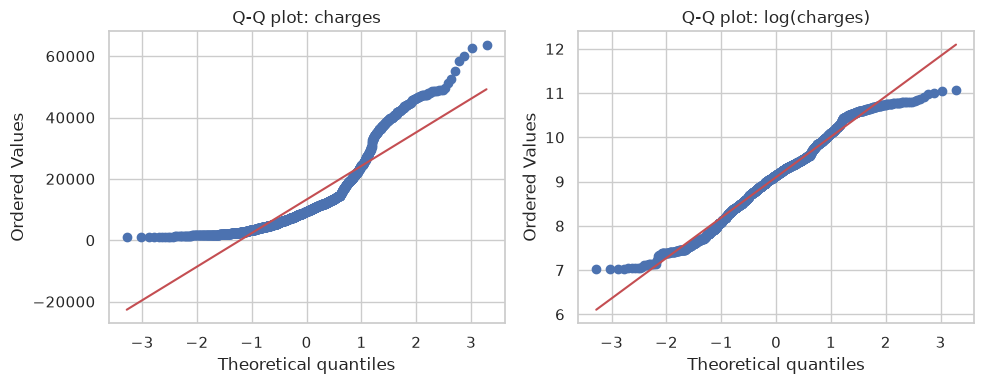

In [11]:
# Q-Q plot kiểm tra giả định chuẩn của charges (câu 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(df["charges"], plot=ax[0]); ax[0].set_title("Q-Q plot: charges")
stats.probplot(np.log(df["charges"]), plot=ax[1]); ax[1].set_title("Q-Q plot: log(charges)")
plt.tight_layout()
plt.savefig("muc3_qqplot.png", dpi=150)
plt.show()